In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt
from functools import partial
import time

# --------------------------------- Internal imports --------------------------------- #
from radiopyo.chemistry.base_chemistry import ReactionRateEnum
from radiopyo.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo.sim_env import SimEnv
from radiopyo.ode_solver import derive, jac, mono_pulse
import radiopyo as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager(csv=False)

In [3]:
file = Path(rf"{rp.__path__[0]}\data\reactions_bio.ron")

In [4]:
beam = ConstantBeam("e", 0.25, max_dose=10)
env = SimEnv.from_ron_file(file)

In [ ]:
3626/60

In [ ]:
kwargs = {}
kwargs["atol"] = 1e-6
kwargs["first_step"] = 1e-5
kwargs["min_step"] = 1e-9
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 150]
tlog = np.arange(-9, -2.9, step=0.1)
t_eval = np.power(10, tlog)
t_eval = np.append(t_eval, np.arange(2e-3, t_span[-1], step=1e-3))
y0 = env.initial_values()
print(y0)

t0 = time.time()
sol = solve_ivp(derive, t_span, y0, args=(env, beam), jac=jac, t_eval=t_eval, **kwargs)
t1 = time.time()
print(f"\t==> Execution time was {t1-t0:.3f} s")

sim_t, res = sol.t, sol.y
len(sim_t)

[ 0.  0.  0.  0.  0. 50.  0.  0.  0.]


In [6]:
sim_t

array([1.00000000e-09, 1.25892541e-09, 1.58489319e-09, 1.99526231e-09,
       2.51188643e-09, 3.16227766e-09, 3.98107171e-09, 5.01187234e-09,
       6.30957344e-09, 7.94328235e-09, 1.00000000e-08, 1.25892541e-08,
       1.58489319e-08, 1.99526231e-08, 2.51188643e-08, 3.16227766e-08,
       3.98107171e-08, 5.01187234e-08, 6.30957344e-08, 7.94328235e-08,
       1.00000000e-07, 1.25892541e-07, 1.58489319e-07, 1.99526231e-07,
       2.51188643e-07, 3.16227766e-07, 3.98107171e-07, 5.01187234e-07,
       6.30957344e-07, 7.94328235e-07, 1.00000000e-06, 1.25892541e-06,
       1.58489319e-06, 1.99526231e-06, 2.51188643e-06, 3.16227766e-06,
       3.98107171e-06, 5.01187234e-06, 6.30957344e-06, 7.94328235e-06,
       1.00000000e-05, 1.25892541e-05, 1.58489319e-05, 1.99526231e-05,
       2.51188643e-05, 3.16227766e-05, 3.98107171e-05, 5.01187234e-05,
       6.30957344e-05, 7.94328235e-05, 1.00000000e-04, 1.25892541e-04,
       1.58489319e-04, 1.99526231e-04, 2.51188643e-04, 3.16227766e-04,
      

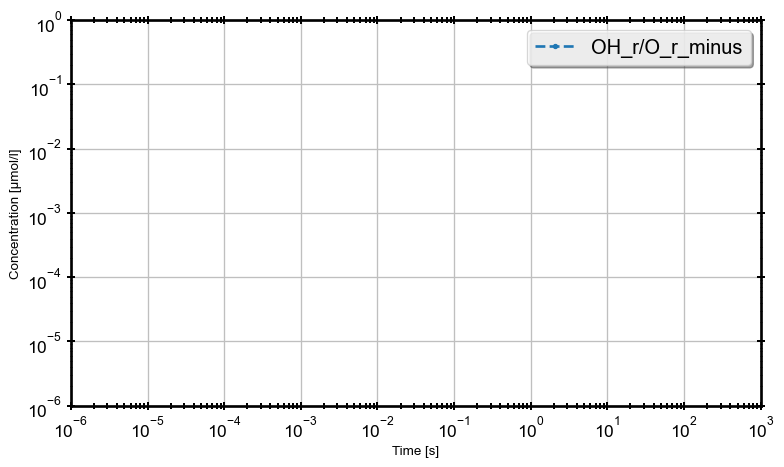

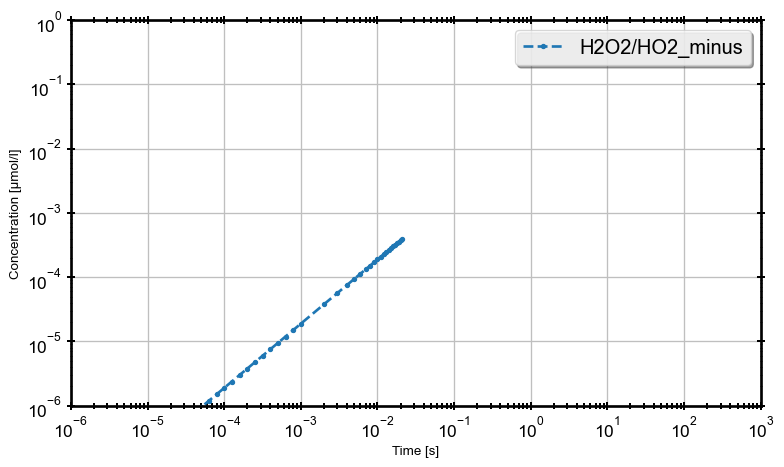

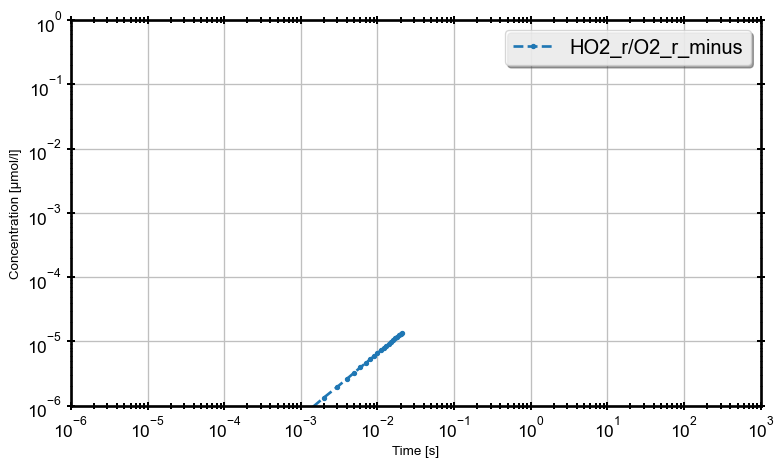

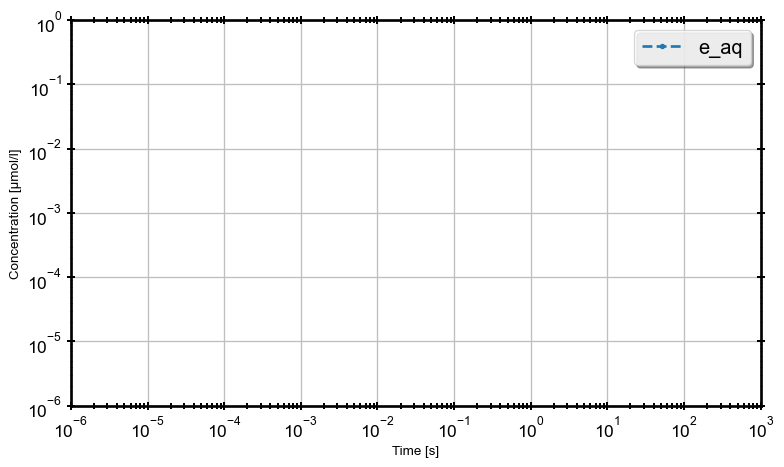

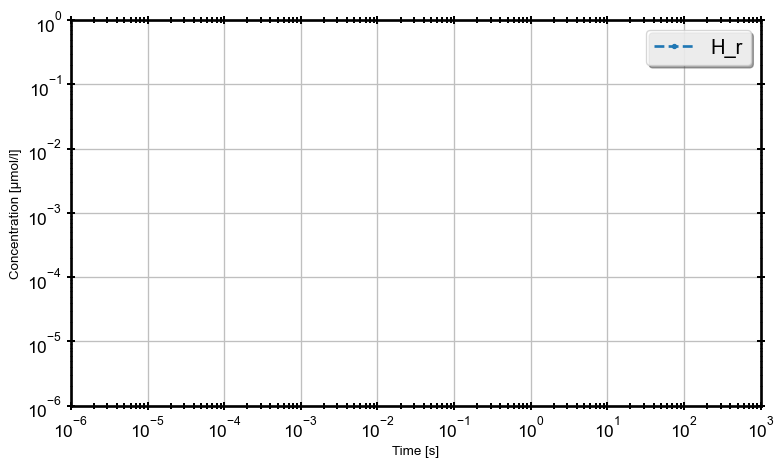

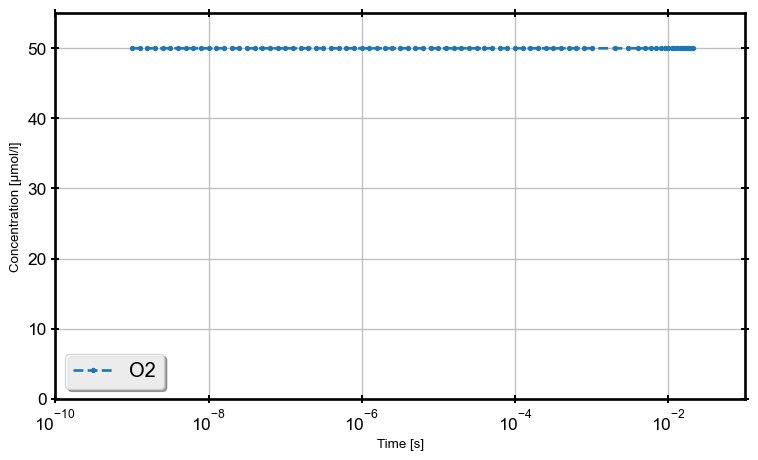

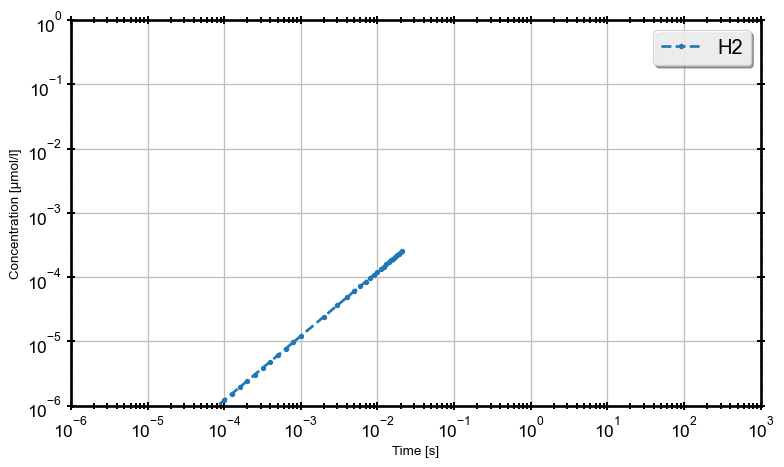

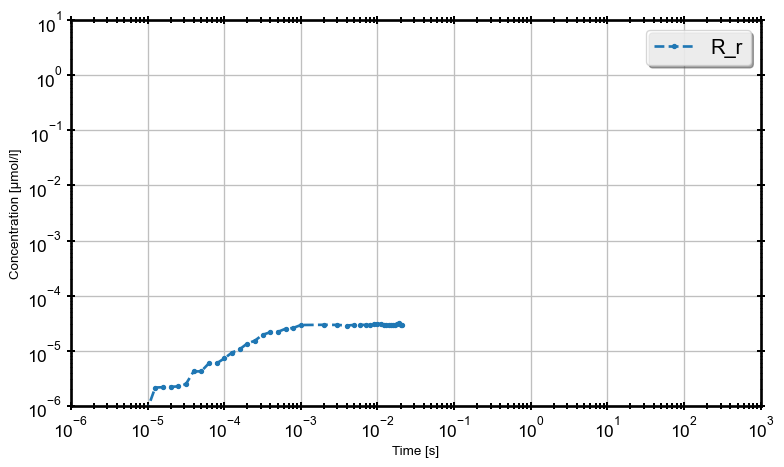

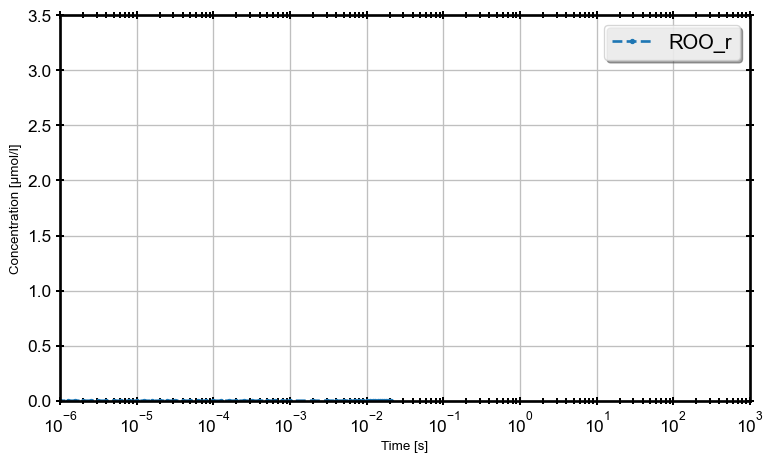

In [7]:
for (label, sp) in zip(env.species_labels(), res):
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        if label == "ROO_r":
            ax.semilogx(sim_t , sp , label=label)
            ax.set_ylim([0, 3.5])
            ax.set_xlim([1e-6, 1e3])
        elif label == "R_r":
            ax.loglog(sim_t , sp , label=label)
            ax.set_ylim([1e-6, 1e1])
            ax.set_xlim([1e-6, 1e3])
        elif label=="O2":
            ax.semilogx(sim_t , sp , label=label)
            ax.set_ylim([0,55])
        else:
            ax.loglog(sim_t , sp , label=label)
            ax.set_xlim([1e-6, 1e3])
            ax.set_ylim([1e-6, 1e0])
        ax.legend(loc='best')
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

        #if label==r"OH_r/O_r_minus":
        #    ax.set_ylim([1e-25, 1])
